In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
from sklearn import linear_model
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import xgboost as xgb
from xgboost import XGBRegressor


In [2]:
waves = pd.read_csv('../Data/waves_2023.txt', sep=r'\s+')

In [3]:
waves.describe()

,YY,MM,DD,hh,mm,WDIR,WSPD,GST,WVHT,DPD,APD,MWD,PRES,ATMP,WTMP,DEWP,VIS,TIDE
count,17285.0,17285.000000,17285.000000,17285.000000,17285.000000,17285.0,17285.0,17285.0,17285.000000,17285.000000,17285.000000,17285.000000,17285.0,17285.0,17285.000000,17285.0,17285.0,17285.0
mean,2023.0,6.526063,15.800579,11.499277,40.985594,999.0,99.0,99.0,1.083535,12.161879,6.813054,234.556205,9999.0,999.0,17.196535,999.0,99.0,99.0
std,0.0,3.467253,8.817920,6.925343,15.007646,0.0,0.0,0.0,2.296129,4.165737,2.803208,49.429981,0.0,0.0,2.564664,0.0,0.0,0.0
min,2023.0,1.000000,1.000000,0.000000,0.000000,999.0,99.0,99.0,0.330000,2.860000,3.420000,10.000000,9999.0,999.0,11.800000,999.0,99.0,99.0
25%,2023.0,4.000000,8.000000,5.000000,26.000000,999.0,99.0,99.0,0.730000,9.090000,5.500000,179.000000,9999.0,999.0,14.600000,999.0,99.0,99.0
50%,2023.0,6.000000,16.000000,11.000000,26.000000,999.0,99.0,99.0,0.880000,12.500000,6.360000,263.000000,9999.0,999.0,17.500000,999.0,99.0,99.0
75%,2023.0,10.000000,23.000000,18.000000,56.000000,999.0,99.0,99.0,1.140000,14.290000,7.550000,271.000000,9999.0,999.0,19.400000,999.0,99.0,99.0
max,2023.0,12.000000,31.000000,23.000000,56.000000,999.0,99.0,99.0,99.000000,99.000000,99.000000,999.000000,9999.0,999.0,23.900000,999.0,99.0,99.0


In [4]:
waves= waves.drop(['WDIR','WSPD','GST','PRES','ATMP','DEWP','VIS','TIDE'], axis=1)
waves.describe()

,YY,MM,DD,hh,mm,WVHT,DPD,APD,MWD,WTMP
count,17285.0,17285.000000,17285.000000,17285.000000,17285.000000,17285.000000,17285.000000,17285.000000,17285.000000,17285.000000
mean,2023.0,6.526063,15.800579,11.499277,40.985594,1.083535,12.161879,6.813054,234.556205,17.196535
std,0.0,3.467253,8.817920,6.925343,15.007646,2.296129,4.165737,2.803208,49.429981,2.564664
min,2023.0,1.000000,1.000000,0.000000,0.000000,0.330000,2.860000,3.420000,10.000000,11.800000
25%,2023.0,4.000000,8.000000,5.000000,26.000000,0.730000,9.090000,5.500000,179.000000,14.600000
50%,2023.0,6.000000,16.000000,11.000000,26.000000,0.880000,12.500000,6.360000,263.000000,17.500000
75%,2023.0,10.000000,23.000000,18.000000,56.000000,1.140000,14.290000,7.550000,271.000000,19.400000
max,2023.0,12.000000,31.000000,23.000000,56.000000,99.000000,99.000000,99.000000,999.000000,23.900000


In [5]:
# WVHT = Wave Height (m)
# DPD = Dominant wave period (seconds)
# APD = Average wave period (seconds)
# MWD = The direction from which the waves at the dominant period (DPD) are coming
# WTMP = Sea surface temperature (Celsius)

waves = waves[waves['WVHT'] < 99]
waves = waves[waves['DPD'] < 99]
waves = waves[waves['APD'] < 99]
waves = waves[waves['MWD'] < 999]

In [6]:
wavesML = waves.drop(['YY','MM','DD','hh','mm'], axis = 1)
wavesML.describe()

,WVHT,DPD,APD,MWD,WTMP
count,17276.000000,17276.000000,17276.000000,17276.000000,17276.000000
mean,1.032525,12.116640,6.765029,234.157965,17.195294
std,0.526637,3.664928,1.852623,46.260000,2.564729
min,0.330000,2.860000,3.420000,10.000000,11.800000
25%,0.730000,9.090000,5.500000,179.000000,14.600000
50%,0.880000,12.500000,6.360000,263.000000,17.500000
75%,1.140000,14.290000,7.550000,271.000000,19.400000
max,5.130000,25.000000,15.790000,306.000000,23.900000


In [7]:
df_X = wavesML.drop(['WVHT'], axis=1).to_numpy().copy()
df_y = wavesML['WVHT'].to_numpy().copy()

X_train, X_test, y_train, y_test = train_test_split(df_X, df_y, test_size=0.10, random_state=38)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.10, random_state=38)

## Question 1: Linear regression vs 25-iteration XGBoost

In [8]:
# Baseline: Linear Regression

regL = LinearRegression()
regL.fit(X_train, y_train)
l_preds = regL.predict(X_test)
rmse = np.sqrt(mean_squared_error(y_test, l_preds))
print(f"Root Mean Squared Error: {rmse:.4f}")


Root Mean Squared Error: 0.4304


In [9]:
#XGBoost Regressor

regXGB = xgb.XGBRegressor(n_estimators=25, learning_rate=0.05, max_depth=6, random_state=38)

regXGB.fit(X_train, y_train)

xgb_preds = regXGB.predict(X_test)
rmse = np.sqrt(mean_squared_error(y_test, xgb_preds))
print(f"Root Mean Squared Error: {rmse:.4f}")


Root Mean Squared Error: 0.3429


In [10]:
# Combine train, validation and test

models = {
    "Linear Regression (regL)": regL,
    "XGBoost Regression": regXGB,
}


print(f"{'Model Variable Name':<30} | {'Dataset':<12} | {'RMSE':<12} | {'R\u00b2':<12}")
print("-" * 70)

for name, model in models.items():
    
    for dataset, X_data, y_data in [("Train", X_train, y_train), 
                                       ("Val", X_val, y_val), 
                                       ("Test", X_test, y_test)]:
        
        preds = model.predict(X_data)
        rmse = np.sqrt(mean_squared_error(y_data, preds))
        r2 = r2_score(y_data, preds)
        
        print(f"{name:<30} | {dataset:<12} | {rmse:<12.4f} | {r2:<12.4f}")
    print("-" * 70)

Model Variable Name            | Dataset      | RMSE         | R²          
----------------------------------------------------------------------
Linear Regression (regL)       | Train        | 0.4444       | 0.2910      
Linear Regression (regL)       | Val          | 0.4368       | 0.3305      
Linear Regression (regL)       | Test         | 0.4304       | 0.2886      
----------------------------------------------------------------------
XGBoost Regression             | Train        | 0.3475       | 0.5665      
XGBoost Regression             | Val          | 0.3479       | 0.5753      
XGBoost Regression             | Test         | 0.3429       | 0.5485      
----------------------------------------------------------------------


**Interpretation of the results:** The 25-iteration XGBoost model performs better than linear regression on all three datasets. XGBoost training, validation, and test RMSE are **0.3475, 0.3479, and 0.3429 m**, compared with **0.4444, 0.4368, and 0.4304 m** for linear regression. XGBoost also has higher R² on every split.

## Question 2: Cost Function

Linear Regressor: Mean Squared Error (Ordinary Least Squares)

XGBoost Regressor: Squared Error with Regularization

## Question 3: Hyperparameters- Using n_estimators

In [11]:
n_iterations_list = [1, 5, 10, 25, 50, 100, 200, 500, 1000]
val_r2 = [] 

for n in n_iterations_list:
    model = xgb.XGBRegressor(n_estimators=n, learning_rate=0.05, max_depth=6, random_state=38)
    model.fit(X_train, y_train)
    val_r2.append(model.score(X_val, y_val)) 
    
best_iterations_index = int(np.argmax(val_r2))
best_n = n_iterations_list[best_iterations_index]
print('Best number of trees based on R²:', best_n)

# Train the final optimized model
xgb_best = xgb.XGBRegressor(n_estimators=best_n, learning_rate=0.05, max_depth=6, random_state=38)
xgb_best.fit(X_train, y_train) 

# Train a baseline 25-tree model to compare against (replaces the missing regXGB variable)
xgb_25 = xgb.XGBRegressor(n_estimators=25, learning_rate=0.05, max_depth=6, random_state=38)
xgb_25.fit(X_train, y_train)

# FIX: Replaced regXGB with xgb_25
print(f'Test R² Score: {xgb_25.score(X_test, y_test):.3f} (25 trees) vs {xgb_best.score(X_test, y_test):.3f} ({best_n} trees)')


Best number of trees based on R²: 500
Test R² Score: 0.548 (25 trees) vs 0.703 (500 trees)


## Question 4: Error vs boosting iterations

In [12]:
iteration_counts = [2, 10, 25, 50, 100, 250, 500, 1000]
train_errors = []
val_errors = []


print(f"{'Iterations':<10} | {'Train RMSE':<10} | {'Val RMSE':<10} | {'RMSE Gap (Val - Train)':<22}")
print("-" * 60)

for n in iteration_counts:
    regXGB = xgb.XGBRegressor(n_estimators=n, learning_rate=0.05, max_depth=6, random_state=38)
    regXGB.fit(X_train, y_train)
    
    # Calculate Training Error (RMSE)
    train_pred = regXGB.predict(X_train)
    train_rmse = np.sqrt(mean_squared_error(y_train, train_pred))
    train_errors.append(train_rmse)
    
    # Calculate Validation Error (RMSE)
    val_pred = regXGB.predict(X_val)
    val_rmse = np.sqrt(mean_squared_error(y_val, val_pred))
    val_errors.append(val_rmse)
    
    # Calculate the exact difference (The Overfitting Gap)
    rmse_diff = val_rmse - train_rmse
    
    print(f"{n:<10} | {train_rmse:<10.4f} | {val_rmse:<10.4f} | {rmse_diff:<22.4f}")

Iterations | Train RMSE | Val RMSE   | RMSE Gap (Val - Train)
------------------------------------------------------------
2          | 0.4993     | 0.5040     | 0.0047                
10         | 0.4176     | 0.4194     | 0.0017                
25         | 0.3475     | 0.3479     | 0.0004                
50         | 0.3120     | 0.3166     | 0.0046                
100        | 0.2877     | 0.3009     | 0.0133                
250        | 0.2553     | 0.2920     | 0.0367                
500        | 0.2203     | 0.2895     | 0.0691                
1000       | 0.1823     | 0.2915     | 0.1092                


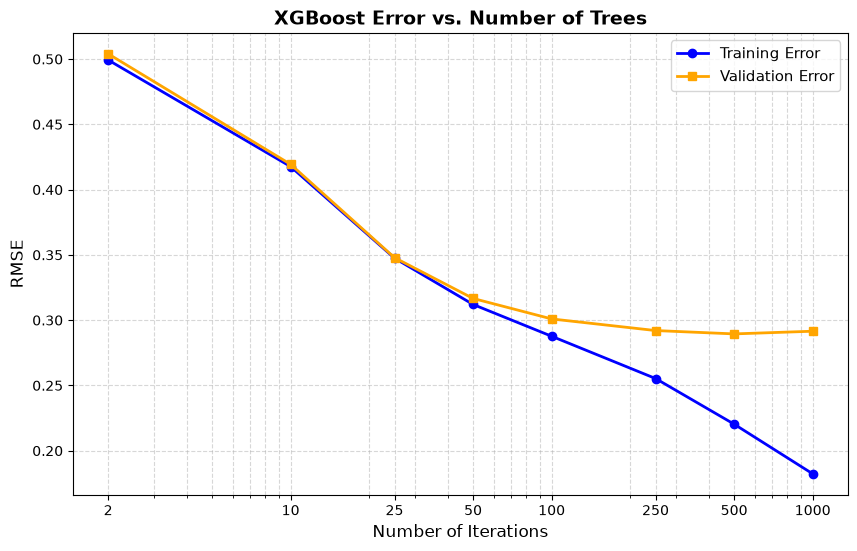

In [13]:
plt.figure(figsize=(10, 6))
plt.plot(iteration_counts, train_errors, marker='o', label='Training Error', color='blue', linewidth=2)
plt.plot(iteration_counts, val_errors, marker='s', label='Validation Error', color='orange', linewidth=2)

plt.title('XGBoost Error vs. Number of Trees', fontsize=14, fontweight='bold')
plt.xlabel('Number of Iterations', fontsize=12)
plt.ylabel('RMSE', fontsize=12)
plt.xscale('log')
plt.xticks(iteration_counts, labels=[str(t) for t in iteration_counts])
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.legend(fontsize=11)
plt.show()

## Question 5: Checking for overfitting at 1,000 iterations

In [14]:
best_index = int(np.argmin(val_errors))
index_1000 = iteration_counts.index(1000)

print("Best iteration count among tested values:",
      iteration_counts[best_index])

print(f"Lowest validation RMSE: {val_errors[best_index]:.4f}")
print(f"Training RMSE at 1,000: {train_errors[index_1000]:.4f}")
print(f"Validation RMSE at 1,000: {val_errors[index_1000]:.4f}")

print(
    "Validation RMSE increase above the lowest value: "
    f"{val_errors[index_1000] - val_errors[best_index]:.4f}"
)

Best iteration count among tested values: 500
Lowest validation RMSE: 0.2895
Training RMSE at 1,000: 0.1823
Validation RMSE at 1,000: 0.2915
Validation RMSE increase above the lowest value: 0.0021


There is slight evidence of overfitting at 1,000 iterations. Validation RMSE reached its lowest value of **0.2895 m at 500 iterations**, then increased to **0.2915 m at 1,000 iterations**, while training RMSE was **0.1823 m**. The small increase in validation error suggests mild overfitting.

## Question 6: Early stopping with a patience of 10

In [15]:
regXGB_early = xgb.XGBRegressor(
    n_estimators=5000,
    learning_rate=0.05,
    max_depth=6,
    random_state=38,
    objective="reg:squarederror",
    eval_metric="rmse",
    early_stopping_rounds=10
)

regXGB_early.fit(X_train, y_train, eval_set=[(X_train, y_train), (X_val, y_val)], verbose=False)


# XGBoost numbers iterations starting from zero.
optimal_iterations = regXGB_early.best_iteration + 1

history = regXGB_early.evals_result()
iterations_run = len(history["validation_1"]["rmse"])

print("Optimal boosting iterations:", optimal_iterations)
print("Total iterations run:", iterations_run)
print(f"Best validation RMSE: {regXGB_early.best_score:.4f}")

if iterations_run == 5000:
    print(
        "The maximum iteration limit was reached. "
        "Increase n_estimators to allow early stopping to finish."
    )

Optimal boosting iterations: 214
Total iterations run: 224
Best validation RMSE: 0.2930


**Results:** The best iteration was **214**, and training stopped after **224** iterations. Validation RMSE was **0.2930 m** and test RMSE was **0.2867 m**.

In [16]:
for name, X_split, y_split in [
    ("Training", X_train, y_train),
    ("Validation", X_val, y_val),
    ("Test", X_test, y_test)
]:
    predictions = regXGB_early.predict(X_split)

    rmse = np.sqrt(mean_squared_error(y_split, predictions))

    print(f"{name:<12} RMSE: {rmse:.4f} m")

Training     RMSE: 0.2621 m
Validation   RMSE: 0.2930 m
Test         RMSE: 0.2867 m


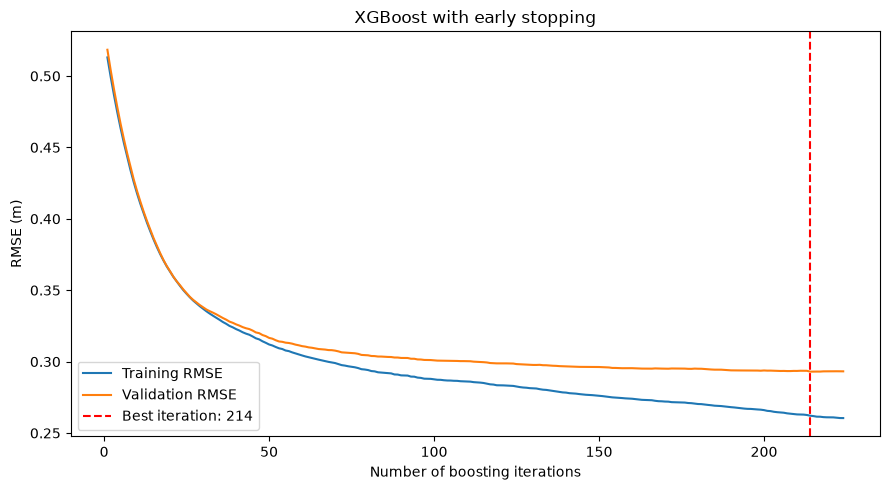

In [17]:
train_history = history["validation_0"]["rmse"]
val_history = history["validation_1"]["rmse"]

rounds = np.arange(1, iterations_run + 1)

plt.figure(figsize=(9, 5))

plt.plot(rounds, train_history, label="Training RMSE")
plt.plot(rounds, val_history, label="Validation RMSE")

plt.axvline(
    optimal_iterations,
    color="red",
    linestyle="--",
    label=f"Best iteration: {optimal_iterations}"
)

plt.xlabel("Number of boosting iterations")
plt.ylabel("RMSE (m)")
plt.title("XGBoost with early stopping")
plt.legend()
plt.tight_layout()
plt.show()